# 02 Velocity decomposition: fault-parallel and vertical velocity maps

```
Created on Wed Sep 23 2026
@author: daniellelindsay
Run in opera_disp_feb13 (MintPy importable, pygmt). Seconds.
```

**What this notebook does.** Takes the GNSS-tied ascending and descending
velocity mosaics (`mosaic/<orbit>_velocity_NA.h5`, from the preparation chain
in notebook 01) and solves, pixel by pixel, for the fault-parallel (FP) and
vertical (Up) velocity. The solve is MintPy's own `asc_desc2horz_vert`, with
the mean strike of the mapped Hayward trace as the horizontal direction. All
horizontal motion is assumed fault-parallel, the standard two-look
assumption (Methods M2).

**Geometry** (definitions from MintPy `utils0.enu2los`; check there, not here):

```
inc_angle  - incidence angle of the LOS vector, measured from vertical
az_angle   - azimuth of the LOS vector FROM THE GROUND TO THE SATELLITE, measured
             from north, ANTI-CLOCKWISE positive.  head_angle = 90 - az_angle.
             Ours: ascending  ~100 (flies N10W, looks east, sits WEST of the pixel)
                   descending ~260 (flies S10E, looks west, sits EAST of the pixel)
strike     - compass bearing clockwise from north = profile_az + 90 (~144, SE).
             MintPy's horz_az_angle is anti-clockwise, so the strike enters as -strike
             (pinned by tests/test_insar_utils.py).
```

**Outputs** (`outputs/02_velocity_decomposition/`):
- `fp_velocity_map.h5` with datasets `fp_velocity` and `up_velocity` (mm/yr)
- `fp_velocity.h5`, `up_velocity.h5` as MintPy velocity files and their `.grd`
  versions from `save_gmt.py`, for GMT / QGIS
- `fp_velocity_xfault_swath200m_dist1000m.csv`: the cross-fault transects at
  the five creepmeters
- `02_velocity_stats.txt` and the registry rows `02_*`

**Figures**: the rotated FP / Up velocity maps (Fig 1a) and the five transects.

**What to check when you run it.** CHECK 1 re-derives the decomposition at
random pixels with our own design matrix and compares with MintPy's numbers;
CHECK 2 fits the fault-crossing step at the five creepmeters (CFW1 should be
~7 mm/yr, the creepmeter's rate); CHECK 3 compares every product with the
previous run of this notebook.

In [1]:
import os

import insar_utils as utils
from TulePond_filepaths import (common_paths, paths_mosaic, creepmeters,
                                unit, az_smooth_n, paths_out, repo_dir)

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import h5py                                      # MintPy HDF5 products
import pyproj                                    # lon/lat -> UTM
import xarray as xr                              # gridded arrays for pygmt
import matplotlib.pyplot as plt                  # quick-look plots
import pygmt                                     # publication maps
import mintpy
from mintpy.asc_desc2horz_vert import asc_desc2horz_vert   # THE decomposition, MintPy's own

## Paths and parameters

In [2]:
notebook = "02_velocity_decomposition_v2"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the products of the previous version of this notebook, for CHECK 3
parity_dir = paths_out["02_velocity_decomposition"]

geom_step = 20        # MintPy medians the geometry in windows of this many pixels (its default)
swath_m = 200.0       # transects: along-fault half-width of the swath (m)
max_dist_m = 1000.0   # transects: cross-fault half-extent (m)
n_check = 200         # pixels re-derived by hand in CHECK 1
rng = np.random.default_rng(0)

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(paths_mosaic["ascending"]["vel_NA_file"], paths_mosaic["ascending"]["geo_file"],
           paths_mosaic["descending"]["vel_NA_file"], paths_mosaic["descending"]["geo_file"],
           common_paths["fault_profiles"])

Registry for 02_velocity_decomposition_v2: run c8ccd551, git b387af5+


## Load InSAR: the two velocity mosaics and their geometry

Both orbits are on the SAME 30 m UTM grid (EPSG 32610), so no resampling is
needed and a pixel in the ascending map is the same ground pixel in the
descending map. Velocities are stored in m/yr and converted to mm/yr on
loading (`unit = 1000`).

In [3]:
insar = {}
for orbit in ("ascending", "descending"):
    print(f"Loading {orbit} mosaic")
    with h5py.File(paths_mosaic[orbit]["vel_NA_file"], "r") as hf:
        vel = hf["velocity"][:] * unit                                  # m/yr -> mm/yr
        attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in hf.attrs.items()}
    with h5py.File(paths_mosaic[orbit]["geo_file"], "r") as hf:
        inc = hf["incidenceAngle"][:].astype(np.float32)               # as stored; MintPy handles the no-data
        azi = hf["azimuthAngle"][:].astype(np.float32)
    insar[orbit] = {"vel": vel, "inc": inc, "azi": azi, "attrs": attrs}
    print(f"   grid {attrs['LENGTH']} x {attrs['WIDTH']} px, {attrs['X_STEP']} m, EPSG {attrs['EPSG']}, "
          f"ref pixel ({attrs['REF_LON']}, {attrs['REF_LAT']}) UTM")
    print(f"   velocity valid {100 * np.isfinite(vel).mean():.1f}%, median {np.nanmedian(vel):+.2f} mm/yr, "
          f"incidence {np.nanmin(inc[inc > 0]):.1f} to {np.nanmax(inc):.1f} deg, azimuth median {np.nanmedian(azi[inc > 0]):.1f} deg")

# the two grids must be the same grid
attrs = insar["ascending"]["attrs"]
for key in ("X_FIRST", "Y_FIRST", "X_STEP", "Y_STEP", "WIDTH", "LENGTH", "EPSG", "REF_LAT", "REF_LON"):
    assert attrs[key] == insar["descending"]["attrs"][key], f"asc/desc grids differ in {key}"
assert attrs["EPSG"] == "32610" and float(attrs["X_STEP"]) == 30.0, "expected a 30 m UTM zone 10 grid"
assert insar["ascending"]["vel"].shape == insar["ascending"]["inc"].shape, "geometry grid differs from velocity grid"

# the ground -> satellite vector points WEST for ascending and EAST for descending
inc_asc, azi_asc = insar["ascending"]["inc"], insar["ascending"]["azi"]
inc_desc, azi_desc = insar["descending"]["inc"], insar["descending"]["azi"]
los_vector_asc = utils.los_unit_vector(np.nanmedian(inc_asc[inc_asc > 0]), np.nanmedian(azi_asc[inc_asc > 0]))
los_vector_desc = utils.los_unit_vector(np.nanmedian(inc_desc[inc_desc > 0]), np.nanmedian(azi_desc[inc_desc > 0]))
assert los_vector_asc[0] < 0 < los_vector_desc[0], "look directions are not asc-west / desc-east: check the azimuth convention"
print("median LOS unit vectors (E, N, U): asc", los_vector_asc.round(3), " desc", los_vector_desc.round(3))

Loading ascending mosaic


   grid 3048 x 2333 px, 30.0 m, EPSG 32610, ref pixel (586935.0, 4155585.0) UTM
   velocity valid 40.8%, median -1.67 mm/yr, incidence 37.9 to 42.7 deg, azimuth median 99.9 deg
Loading descending mosaic
   grid 3048 x 2333 px, 30.0 m, EPSG 32610, ref pixel (586935.0, 4155585.0) UTM
   velocity valid 37.7%, median +0.41 mm/yr, incidence 41.8 to 46.0 deg, azimuth median 260.5 deg


median LOS unit vectors (E, N, U): asc [-0.638 -0.112  0.762]  desc [ 0.685 -0.114  0.719]


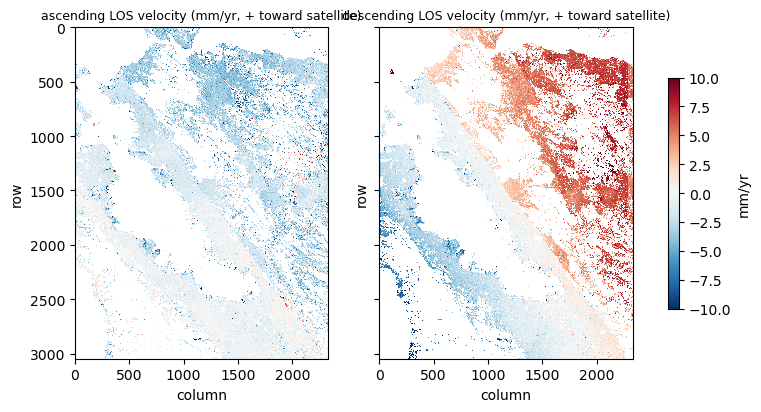

In [4]:
# quick look: both LOS velocity mosaics on their native grid
fig, axes = plt.subplots(1, 2, figsize=(9, 5), sharex=True, sharey=True)
for ax, orbit in zip(axes, ("ascending", "descending")):
    im = ax.imshow(insar[orbit]["vel"], cmap="RdBu_r", vmin=-10, vmax=10, interpolation="none")
    ax.set_title(f"{orbit} LOS velocity (mm/yr, + toward satellite)", fontsize=9)
    ax.set_xlabel("column")
    ax.set_ylabel("row")
fig.colorbar(im, ax=axes, shrink=0.6, label="mm/yr")
plt.show()

## Fault trace: the one strike that enters the decomposition

`hayward_fault_profiles.csv` is the mapped trace every 100 m (built in
notebook 01): `ft_lon, ft_lat, profile_az`, `profile_az` the cross-fault
azimuth pointing to the east side. The 21-crossing (2.1 km) rolling median
removes the digitising kinks and keeps the real bends (the same smoothing as
notebook 03). A raster row has no tectonic meaning, so ONE strike, the mean of
the smoothed local strike, is used for the whole map; where the local strike
matters (the creep time series) notebook 03 applies it crossing by crossing.

In [5]:
x_fault = pd.read_csv(common_paths["fault_profiles"])
x_fault["az_smooth"] = x_fault["profile_az"].rolling(az_smooth_n, center=True, min_periods=3).median()
x_fault["strike"] = x_fault["az_smooth"] + 90.0                 # compass bearing, pointing SE along the fault
strike = float(np.nanmean(x_fault["strike"]))

print(f"trace: {len(x_fault)} crossings, latitude {x_fault.ft_lat.min():.3f} to {x_fault.ft_lat.max():.3f}")
print(f"local strike ranges {np.nanmin(x_fault.strike):.1f} to {np.nanmax(x_fault.strike):.1f} deg")
print(f"mean strike used for the map: {strike:.2f} deg (compass bearing, clockwise from north)")
assert 130 < strike < 160, "the Hayward strikes ~N36W; a mean strike outside 130-160 means the trace file is wrong"

trace: 791 crossings, latitude 37.414 to 37.991
local strike ranges 135.8 to 158.2 deg
mean strike used for the map: 144.10 deg (compass bearing, clockwise from north)


## RUN: MintPy's two-look decomposition

`asc_desc2horz_vert` solves, in windows of `geom_step` x `geom_step` pixels
with the window-median geometry,

$$ \begin{bmatrix} d_{asc} \\ d_{desc} \end{bmatrix} =
   \begin{bmatrix} \sin\theta_a \cos(\alpha_a - \alpha_h) & \cos\theta_a \\
                   \sin\theta_d \cos(\alpha_d - \alpha_h) & \cos\theta_d \end{bmatrix}
   \begin{bmatrix} v_{FP} \\ v_{U} \end{bmatrix} $$

with $\alpha_h$ = `-strike`. Pixels missing on either track are set to NaN on
both so the solve never mixes a valid value with a zero.

In [6]:
vel_asc, vel_desc = insar["ascending"]["vel"], insar["descending"]["vel"]
both = np.isfinite(vel_asc) & np.isfinite(vel_desc)
print(f"pixels valid on both tracks: {both.sum()} ({100 * both.mean():.1f}% of the grid)")

los_vel = np.stack([vel_asc, vel_desc]).astype(np.float32)
los_vel[:, ~both] = np.nan
los_inc = np.stack([inc_asc, inc_desc]).astype(np.float32)
los_azi = np.stack([azi_asc, azi_desc]).astype(np.float32)

fp_vel, up_vel = asc_desc2horz_vert(los_vel, los_inc, los_azi, horz_az_angle=-strike, step=geom_step)
fp_vel, up_vel = fp_vel.astype(np.float64), up_vel.astype(np.float64)

print("")
print(f"FP velocity: {100 * np.isfinite(fp_vel).mean():.1f}% valid, median {np.nanmedian(fp_vel):+.2f} mm/yr, "
      f"5-95% {np.nanpercentile(fp_vel, 5):+.2f} to {np.nanpercentile(fp_vel, 95):+.2f}")
print(f"Up velocity: median {np.nanmedian(up_vel):+.2f} mm/yr, 5-95% {np.nanpercentile(up_vel, 5):+.2f} to {np.nanpercentile(up_vel, 95):+.2f}")

pixels valid on both tracks: 2410694 (33.9% of the grid)
decomposing asc/desc into horz/vert direction in windows of 20x20 ...
[>                                                 ]

[>                                                 ]

[>                        2%                       ] 3/153    0s /     2s

[=>                       3%                       ] 4/153    0s /     2s

[=>                       3%                       ] 5/153    0s /     2s

[=>                       4%                       ] 6/153    0s /     2s

... (146 outputs left out)

[==================================================] 152/153

[==================================================] 153/153

FP velocity: 33.5% valid, median +1.39 mm/yr, 5-95% -4.44 to +13.16


Up velocity: median -0.87 mm/yr, 5-95% -3.53 to +1.82


## CHECK 1: re-derive the decomposition by hand at random pixels

MintPy is a black box to the reader, so the solve is redone at `n_check`
random pixels with `utils.design_matrix_up_fp` (our own, tested design
matrix) and `numpy.linalg.solve`, using the same window-median geometry
MintPy uses. Agreement to 1e-3 mm/yr (float32 storage) means our convention
and MintPy's are the same thing.

In [7]:
# MintPy returns NaN where a window has no valid geometry; report, then compare only where it returned a number
lost = both & ~np.isfinite(fp_vel)
print(f"pixels valid on both tracks but NaN after the solve: {lost.sum()} ({100 * lost.sum() / both.sum():.2f}%)")

rows, cols = np.where(both & np.isfinite(fp_vel))
pick = rng.choice(len(rows), size=n_check, replace=False)
diff_fp, diff_up = [], []
for row, col in zip(rows[pick], cols[pick]):
    # MintPy's geometry window for this pixel: the geom_step x geom_step block it falls in
    row_0, col_0 = (row // geom_step) * geom_step, (col // geom_step) * geom_step
    inc_window = np.nanmedian(los_inc[:, row_0:row_0 + geom_step, col_0:col_0 + geom_step], axis=(1, 2))
    azi_window = np.nanmedian(los_azi[:, row_0:row_0 + geom_step, col_0:col_0 + geom_step], axis=(1, 2))
    G = utils.design_matrix_up_fp(inc_window, azi_window, strike)               # columns [U, FP]
    up_hand, fp_hand = np.linalg.solve(G, [vel_asc[row, col], vel_desc[row, col]])
    diff_fp.append(fp_hand - fp_vel[row, col])
    diff_up.append(up_hand - up_vel[row, col])
diff_fp, diff_up = np.array(diff_fp), np.array(diff_up)

print(f"hand solve minus MintPy at {n_check} pixels: FP max |diff| {np.abs(diff_fp).max():.2e} mm/yr, "
      f"Up max |diff| {np.abs(diff_up).max():.2e} mm/yr")
assert np.abs(diff_fp).max() < 1e-3 and np.abs(diff_up).max() < 1e-3, "our design matrix and MintPy disagree"
print("PASS: MintPy's decomposition equals ours (same convention, same numbers)")

pixels valid on both tracks but NaN after the solve: 29265 (1.21%)


hand solve minus MintPy at 200 pixels: FP max |diff| 6.25e-06 mm/yr, Up max |diff| 3.52e-06 mm/yr
PASS: MintPy's decomposition equals ours (same convention, same numbers)


## CHECK 2: the sign and size of the fault-parallel step at the creepmeters

Right-lateral creep means the EAST block moves south-east relative to the
west block. FP is positive along the strike bearing (south-east), so the east
side of the trace must be MORE positive than the west side. At each
creepmeter a cross-fault transect is cut from the FP map (every finite pixel
within +/- `swath_m` along the fault and +/- `max_dist_m` across, centred on
the trace point nearest the instrument) and fitted with
`v = a + b d + step H(d > 0)`: the step is the creep rate seen by the
velocity field, to compare with the creepmeter (CFW1 7.0 mm/yr).

In [8]:
def step_fit(dist, vel):
    """v = a + b*d + step*[d > 0]; the step is the fault-crossing creep rate.
    Solved by least squares (three unknowns, so linregress alone cannot do it)."""
    G = np.column_stack([np.ones_like(dist), dist, (dist > 0).astype(float)])
    a, b, step = np.linalg.lstsq(G, vel, rcond=None)[0]
    return step, a + b * dist + step * (dist > 0)


# UTM position of every crossing, and the pixel grid
utm = pyproj.Transformer.from_crs(4326, int(attrs["EPSG"]), always_xy=True)
x_fault["easting"], x_fault["northing"] = utm.transform(x_fault["ft_lon"].values, x_fault["ft_lat"].values)
x_first, x_step = float(attrs["X_FIRST"]), float(attrs["X_STEP"])
y_first, y_step = float(attrs["Y_FIRST"]), float(attrs["Y_STEP"])
n_rows, n_cols = fp_vel.shape
pixel_m = abs(x_step)

# the transects: walk a grid of points across (dist) and along (offset) the fault at each creepmeter
# and read the FP pixel under each point
transect_rows = []
for code, la, lo, name in creepmeters:
    row = x_fault.loc[(x_fault.ft_lat - la).abs().idxmin()]              # the trace point nearest the creepmeter
    cross_az = np.deg2rad(row["az_smooth"])                              # cross-fault direction, toward the east side
    along_az = np.deg2rad(row["strike"])                                 # along the fault
    n_pixels = 0
    for dist in np.arange(-max_dist_m, max_dist_m + pixel_m, pixel_m):          # across the fault, + = east
        for offset in np.arange(-swath_m, swath_m + pixel_m, pixel_m):          # along the fault
            easting = row["easting"] + dist * np.sin(cross_az) + offset * np.sin(along_az)
            northing = row["northing"] + dist * np.cos(cross_az) + offset * np.cos(along_az)
            col = int(round((easting - x_first) / x_step))
            pixel_row = int(round((northing - y_first) / y_step))
            if 0 <= pixel_row < n_rows and 0 <= col < n_cols and np.isfinite(fp_vel[pixel_row, col]):
                transect_rows.append((code, float(dist), float(fp_vel[pixel_row, col])))
                n_pixels += 1
    print(f"  transect {code} ({name}, lat {la}): {n_pixels} finite pixels")
x_fault_transects = pd.DataFrame(transect_rows, columns=["code", "dist_m", "fp_vel"])
transects_csv = os.path.join(out_dir, f"fp_velocity_xfault_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.csv")
x_fault_transects.to_csv(transects_csv, index=False)
print(f"Saved transects to: {transects_csv}")

steps = {}
print("")
print("fault-parallel velocity step across the trace (east minus west, mm/yr):")
for code, la, lo, name in creepmeters:
    transect = x_fault_transects[x_fault_transects.code == code]
    step, fit = step_fit(transect.dist_m.values, transect.fp_vel.values)
    # the simplest route to the same number: median of the near-field east side minus the west side
    east = transect[(transect.dist_m > 0) & (transect.dist_m <= 300)].fp_vel.median()
    west = transect[(transect.dist_m < 0) & (transect.dist_m >= -300)].fp_vel.median()
    steps[code] = step
    print(f"  {code}: step fit {step:5.2f}   |   median(east 0-300 m) - median(west) = {east - west:5.2f}")
    assert step > 0, f"{code}: negative step means the east block moves NW: the sign convention is wrong"
print("PASS: every creepmeter site shows a right-lateral (positive) step")

  transect CPP1 (Pinole Point, lat 37.9895): 425 finite pixels
  transect CTM1 (Temescal, lat 37.8439): 674 finite pixels
  transect COZ1 (Oakland Zoo, lat 37.7535): 741 finite pixels
  transect CHP1 (Palisade Street, lat 37.66274): 839 finite pixels
  transect CFW1 (Fremont, lat 37.53237): 953 finite pixels
Saved transects to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/fp_velocity_xfault_swath200m_dist1000m.csv

fault-parallel velocity step across the trace (east minus west, mm/yr):
  CPP1: step fit  3.77   |   median(east 0-300 m) - median(west) =  4.65
  CTM1: step fit  3.74   |   median(east 0-300 m) - median(west) =  4.26
  COZ1: step fit  3.15   |   median(east 0-300 m) - median(west) =  3.33
  CHP1: step fit  4.96   |   median(east 0-300 m) - median(west) =  4.78
  CFW1: step fit  6.68   |   median(east 0-300 m) - median(west) =  6.93
PASS: every creepmeter site shows a right-lateral (positive) step


## Save the maps: MintPy files, GMT grids, and the combined product

`fp_velocity.h5` and `up_velocity.h5` are written as MintPy velocity files
(attributes grafted from the mosaic), so MintPy's own tools work on them, and
converted to `.grd` with `save_gmt.py` for GMT and QGIS. The combined
`fp_velocity_map.h5` carries both datasets and the strike used.

In [9]:
src_file = paths_mosaic["ascending"]["vel_NA_file"]
provenance = {"PROVENANCE": utils.provenance_stamp(notebook, repo_dir), "FAULT_AZIMUTH_DEG": strike, "UNIT": "mm/year"}
for name, velocity in (("fp_velocity", fp_vel), ("up_velocity", up_vel)):
    h5_file = os.path.join(out_dir, f"{name}.h5")
    utils.write_new_h5(velocity, h5_file, src_file, dataset="velocity", extra_attrs=provenance)
    utils.run_command(["save_gmt.py", h5_file, "-o", os.path.join(out_dir, f"{name}.grd")])

map_h5 = os.path.join(out_dir, "fp_velocity_map.h5")
with h5py.File(map_h5, "w") as hf:
    hf.create_dataset("fp_velocity", data=fp_vel.astype(np.float32), compression="gzip")
    hf.create_dataset("up_velocity", data=up_vel.astype(np.float32), compression="gzip")
    for key in ("X_FIRST", "Y_FIRST", "X_STEP", "Y_STEP", "WIDTH", "LENGTH", "EPSG", "REF_LAT", "REF_LON"):
        hf.attrs[key] = attrs[key]
    for key, value in provenance.items():
        hf.attrs[key] = str(value)
print(f"Saved FP + Up maps to: {map_h5}")

Saved velocity to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/fp_velocity.h5
Running: /Users/dlindsay/miniforge3/envs/opera_disp_feb13/bin/save_gmt.py /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/fp_velocity.h5 -o /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/fp_velocity.grd


writing >>> /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/fp_velocity.grd
Done.
Saved velocity to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/up_velocity.h5
Running: /Users/dlindsay/miniforge3/envs/opera_disp_feb13/bin/save_gmt.py /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/up_velocity.h5 -o /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/up_velocity.grd


writing >>> /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/up_velocity.grd
Done.


Saved FP + Up maps to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/fp_velocity_map.h5


## CHECK 3: the same as the previous version

The FP and Up maps and the transects must equal the ones the previous
version of this notebook wrote (same data, same solve).

In [10]:
old_map = os.path.join(parity_dir, "fp_velocity_map.h5")
if os.path.exists(old_map):
    with h5py.File(old_map, "r") as hf:
        for name, velocity in (("fp_velocity", fp_vel), ("up_velocity", up_vel)):
            old = hf[name][:].astype(np.float64)
            assert old.shape == velocity.shape
            assert np.array_equal(np.isnan(old), np.isnan(velocity)), f"{name}: NaN pattern differs"
            diff = np.nanmax(np.abs(old - velocity.astype(np.float32).astype(np.float64)))
            print(f"{name}: same {old.shape}, max |difference| {diff:.2e} mm/yr")
            assert diff < 1e-9, f"{name} differs from the previous version"
    old = pd.read_csv(os.path.join(parity_dir, os.path.basename(transects_csv)))
    assert old.shape == x_fault_transects.shape and (old.code == x_fault_transects.code).all()
    diff = np.abs(old[["dist_m", "fp_vel"]].values - x_fault_transects[["dist_m", "fp_vel"]].values).max()
    print(f"{os.path.basename(transects_csv)}: same {old.shape}, max |difference| {diff:.2e}")
    assert diff < 1e-9
else:
    print(f"no previous products at {parity_dir}; check skipped")

fp_velocity: same (3048, 2333), max |difference| 0.00e+00 mm/yr
up_velocity: same (3048, 2333), max |difference| 0.00e+00 mm/yr
fp_velocity_xfault_swath200m_dist1000m.csv: same (3632, 3), max |difference| 1.78e-15


## Figure: the rotated velocity maps

The maps are drawn in the strike-rotated frame used throughout the paper:
`u` runs along the mean strike from Point Pinole (0 km) increasing SOUTH, `v`
is the cross-fault distance with the EAST side positive. Nothing is bent: the
raster is looked up (nearest neighbour, no interpolation, so masked
landslides stay masked) at the rotated grid points, and the curved trace is
drawn on top. The panel is Cartesian km at true aspect, so the scale bar is
exact.

In [11]:
# the strike frame: unit vectors along the mean strike (SE) and across it (NE = east side), in UTM metres
strike_rad = np.deg2rad(strike)
along_e, along_n = np.sin(strike_rad), np.cos(strike_rad)
cross_e, cross_n = -np.cos(strike_rad), np.sin(strike_rad)
# the trace in that frame; u zero at Point Pinole (the northern end), v zero at the trace's median offset
trace_u = x_fault["easting"].values * along_e + x_fault["northing"].values * along_n
trace_v = x_fault["easting"].values * cross_e + x_fault["northing"].values * cross_n
pinole = int(np.argmax(x_fault["ft_lat"].values))
u_origin, v_origin = float(trace_u[pinole]), float(np.median(trace_v))
x_fault["u_km"] = (trace_u - u_origin) / 1e3
x_fault["v_km"] = (trace_v - v_origin) / 1e3
u_south = float(x_fault["u_km"].max())

# the creepmeters along the same axis
u_creepmeter = {}
for code, la, lo, name in creepmeters:
    easting, northing = utm.transform(lo, la)
    u_creepmeter[code] = float(((easting * along_e + northing * along_n) - u_origin) / 1e3)
print(f"trace runs u = 0 (Point Pinole) to {u_south:.1f} km; creepmeters at " +
      ", ".join(f"{code} {u:.1f}" for code, u in u_creepmeter.items()))


def rotated_map(velocity, u_start, u_end, half_km, step_m=90.0):
    """The map resampled onto the (u, v) frame by nearest-neighbour lookup of the UTM pixel under each node."""
    u_axis = np.arange(u_start, u_end, step_m / 1e3)
    v_axis = np.arange(-half_km, half_km + step_m / 1e3, step_m / 1e3)
    u_grid, v_grid = np.meshgrid(u_axis, v_axis)
    easting = (u_grid * 1e3 + u_origin) * along_e + (v_grid * 1e3 + v_origin) * cross_e      # inverse rotation
    northing = (u_grid * 1e3 + u_origin) * along_n + (v_grid * 1e3 + v_origin) * cross_n
    col_index = np.round((easting - x_first) / x_step).astype(int)
    row_index = np.round((northing - y_first) / y_step).astype(int)
    on_grid = (col_index >= 0) & (col_index < n_cols) & (row_index >= 0) & (row_index < n_rows)
    out = np.full(u_grid.shape, np.nan)
    out[on_grid] = velocity[row_index[on_grid], col_index[on_grid]]
    return xr.DataArray(out, coords={"y": v_axis, "x": u_axis}, dims=("y", "x"))


map_half_km = 8.0
ref_patch_km = 5.0    # display reference: mean over the CTM1-COZ1 fault-straddling patch, +/- this across the fault
fp_rot = rotated_map(fp_vel, -3.0, u_south + 3.0, map_half_km)
up_rot = rotated_map(up_vel, -3.0, u_south + 3.0, map_half_km)
# for DISPLAY only (the saved maps keep the ZOA1 datum): subtract the mean of a fault-straddling
# patch between CTM1 and COZ1, as the legacy figure does, so the fault sits at zero, blue west, red east
u_lo, u_hi = sorted([u_creepmeter["CTM1"], u_creepmeter["COZ1"]])
for name, grid in (("FP", fp_rot), ("Up", up_rot)):
    ref = float(np.nanmean(grid.sel(x=slice(u_lo, u_hi), y=slice(-ref_patch_km, ref_patch_km)).values))
    grid -= ref
    print(f"{name} map display reference (CTM1-COZ1 patch mean): {ref:+.2f} mm/yr removed")

trace runs u = 0 (Point Pinole) to 78.5 km; creepmeters at CPP1 0.3, CTM1 20.0, COZ1 32.1, CHP1 44.2, CFW1 62.2
FP map display reference (CTM1-COZ1 patch mean): +2.38 mm/yr removed
Up map display reference (CTM1-COZ1 patch mean): -1.30 mm/yr removed


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-22/fig02_velocity_maps_rotated_strike144.1_clim5-3mm.png


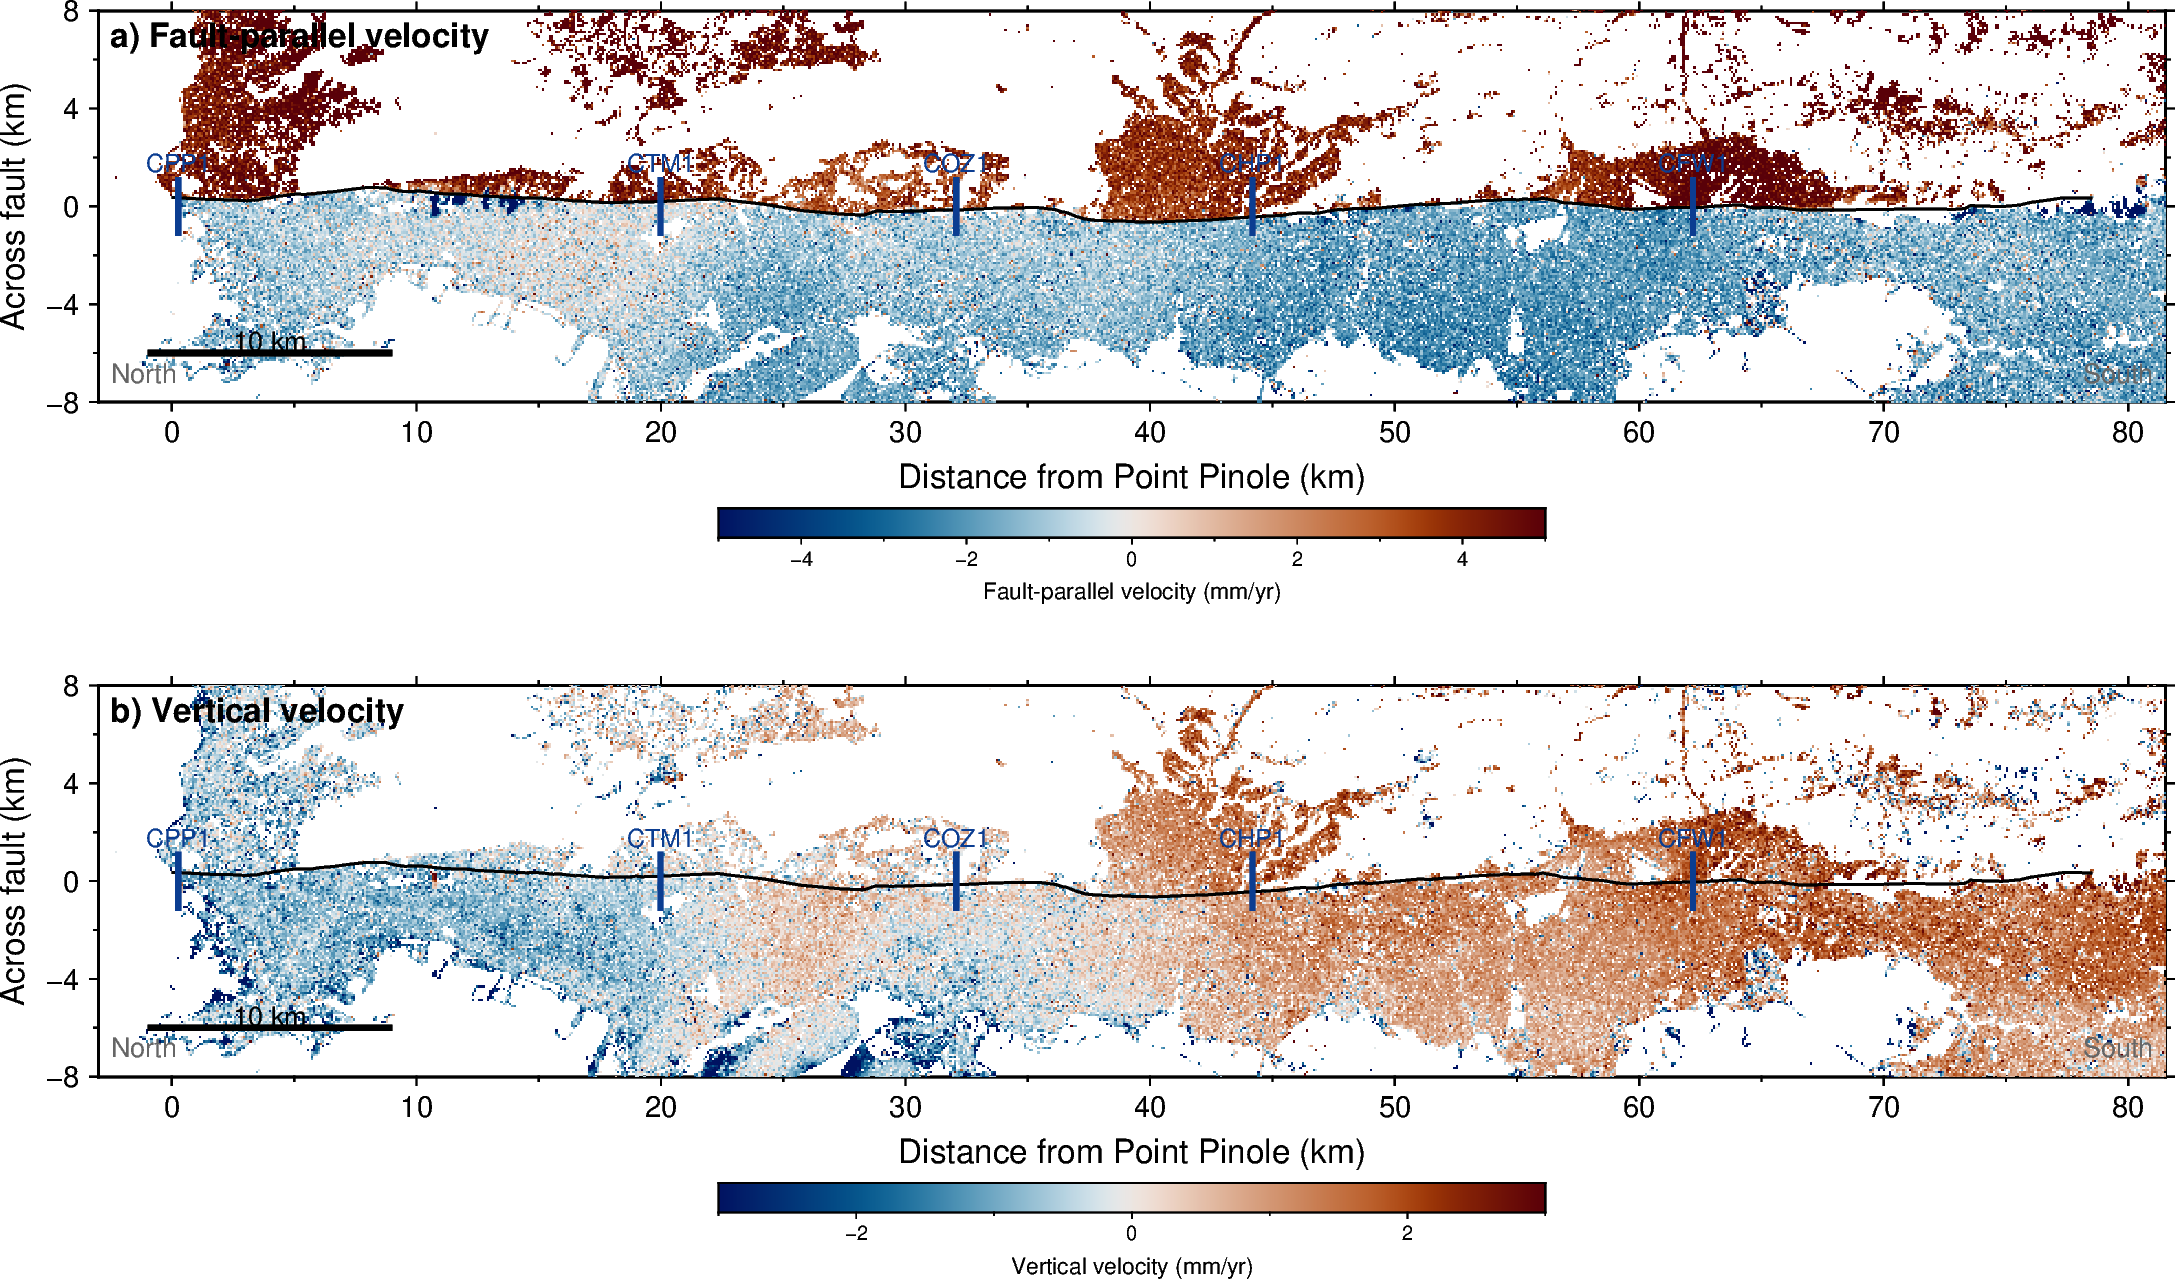

In [12]:
# the figure: two rotated map panels, journal double-column width, drawn the same way twice
W = 17.5                                            # cm: panel width (double column)
region = [-3.0, u_south + 3.0, -map_half_km, map_half_km]
H = W * (2 * map_half_km) / (region[1] - region[0])  # height at true aspect

fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p", FONT_LABEL="8p",
             MAP_FRAME_TYPE="plain", MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p")

# a) fault-parallel velocity
pygmt.makecpt(cmap="vik", series=[-5, 5])
fig.basemap(region=region, projection=f"X{W}c/{H}c",
            frame=["WSne", "xa10f5+lDistance from Point Pinole (km)", "ya4f2+lAcross fault (km)"])
fig.grdimage(grid=fp_rot, cmap=True, nan_transparent=True)
fig.plot(x=x_fault["u_km"], y=x_fault["v_km"], pen="0.6p,black")                    # the mapped trace
for code, u in u_creepmeter.items():                                                 # creepmeter ticks
    fig.plot(x=[u, u], y=[-1.2, 1.2], pen="1.4p,#0b3d91")
    fig.text(x=u, y=1.4, text=code, justify="BC", font="6p,Helvetica,#0b3d91")
fig.text(x=region[0], y=region[3], text="a) Fault-parallel velocity", justify="TL", offset="0.1c/-0.1c", font="8p,Helvetica-Bold")
fig.text(x=region[0] + 0.5, y=-map_half_km + 0.8, text="North", justify="LB", font="6.5p,gray40")
fig.text(x=region[1] - 0.5, y=-map_half_km + 0.8, text="South", justify="RB", font="6.5p,gray40")
fig.plot(x=[region[0] + 2, region[0] + 12], y=[-map_half_km + 2.0] * 2, pen="1.5p,black")   # 10 km scale bar
fig.text(x=region[0] + 7, y=-map_half_km + 2.1, text="10 km", justify="BC", font="6.5p")
fig.colorbar(cmap=True, position=f"JBC+o0c/0.9c+w{W * 0.4}c/0.25c+h", frame="xa2f1+lFault-parallel velocity (mm/yr)")

# b) vertical velocity, below
fig.shift_origin(yshift=f"-{H + 2.4}c")
pygmt.makecpt(cmap="vik", series=[-3, 3])
fig.basemap(region=region, projection=f"X{W}c/{H}c",
            frame=["WSne", "xa10f5+lDistance from Point Pinole (km)", "ya4f2+lAcross fault (km)"])
fig.grdimage(grid=up_rot, cmap=True, nan_transparent=True)
fig.plot(x=x_fault["u_km"], y=x_fault["v_km"], pen="0.6p,black")
for code, u in u_creepmeter.items():
    fig.plot(x=[u, u], y=[-1.2, 1.2], pen="1.4p,#0b3d91")
    fig.text(x=u, y=1.4, text=code, justify="BC", font="6p,Helvetica,#0b3d91")
fig.text(x=region[0], y=region[3], text="b) Vertical velocity", justify="TL", offset="0.1c/-0.1c", font="8p,Helvetica-Bold")
fig.text(x=region[0] + 0.5, y=-map_half_km + 0.8, text="North", justify="LB", font="6.5p,gray40")
fig.text(x=region[1] - 0.5, y=-map_half_km + 0.8, text="South", justify="RB", font="6.5p,gray40")
fig.plot(x=[region[0] + 2, region[0] + 12], y=[-map_half_km + 2.0] * 2, pen="1.5p,black")
fig.text(x=region[0] + 7, y=-map_half_km + 2.1, text="10 km", justify="BC", font="6.5p")
fig.colorbar(cmap=True, position=f"JBC+o0c/0.9c+w{W * 0.4}c/0.25c+h", frame="xa2f1+lVertical velocity (mm/yr)")

stem = os.path.join(fig_dir, f"fig02_velocity_maps_rotated_strike{strike:.1f}_clim5-3mm")
fig.savefig(stem + ".png", dpi=300, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
fig.savefig(stem + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved figure to:", stem + ".png")
fig.show()

## Figure: the five creepmeter transects

Grey points are every pixel in the 400 m swath, the line is the step fit.
The step at CFW1 (Fremont) is the number compared with the creepmeter in
notebook 05; here it is a sanity check that the decomposition produced
right-lateral creep of the right size everywhere along the fault.

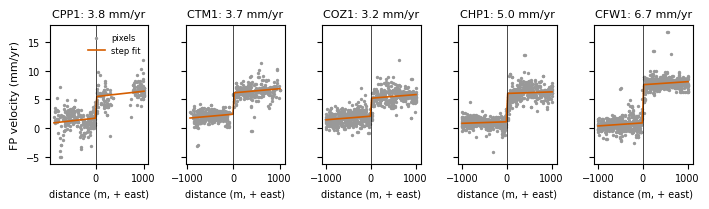

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(7.2, 2.2), sharey=True)
for ax, (code, la, lo, name) in zip(axes, creepmeters):
    transect = x_fault_transects[x_fault_transects.code == code].sort_values("dist_m")
    step, fit = step_fit(transect.dist_m.values, transect.fp_vel.values)
    ax.scatter(transect.dist_m, transect.fp_vel, s=2, color="0.6", label="pixels")
    ax.plot(transect.dist_m, fit, color="#D55E00", lw=1.2, label="step fit")
    ax.axvline(0, color="k", lw=0.5)
    ax.set_title(f"{code}: {step:.1f} mm/yr", fontsize=8)
    ax.set_xlabel("distance (m, + east)", fontsize=7)
    ax.tick_params(labelsize=7)
axes[0].set_ylabel("FP velocity (mm/yr)", fontsize=8)
axes[0].legend(fontsize=6, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f"fig02_transects_swath{swath_m:.0f}m_dist{max_dist_m:.0f}m.png"), dpi=300)
plt.show()

## REGISTER

In [14]:
lines = [
    "02 VELOCITY DECOMPOSITION",
    f"inputs: GNSS-tied velocity mosaics, {attrs['LENGTH']} x {attrs['WIDTH']} px at {attrs['X_STEP']} m, EPSG {attrs['EPSG']}",
    f"mean fault strike used for the map: {strike:.2f} deg (clockwise from north)",
    f"pixels valid on both tracks: {both.sum()} ({100 * both.mean():.1f}%)",
    f"FP velocity median {np.nanmedian(fp_vel):+.2f} mm/yr, 5-95% {np.nanpercentile(fp_vel, 5):+.2f} to {np.nanpercentile(fp_vel, 95):+.2f}",
    f"Up velocity median {np.nanmedian(up_vel):+.2f} mm/yr, 5-95% {np.nanpercentile(up_vel, 5):+.2f} to {np.nanpercentile(up_vel, 95):+.2f}",
    f"hand re-derivation at {n_check} px: max |diff| FP {np.abs(diff_fp).max():.1e}, Up {np.abs(diff_up).max():.1e} mm/yr",
    "",
    "cross-fault FP velocity step at the creepmeters (east - west, mm/yr):",
] + [f"  {code}: {steps[code]:.2f}" for code in steps] + [
    "",
    f"MintPy {mintpy.__version__} (site-packages install in opera_disp_feb13)",
]
sidecar = REG.sidecar("02_velocity", lines)

REG.register("02_strike_mean_deg", strike, "deg", 2, where="M2", cell="strike", sidecar=sidecar)
REG.register("02_fp_valid_pct", 100 * np.isfinite(fp_vel).mean(), "pct", 1, where="M2", cell="decompose", sidecar=sidecar)
REG.register("02_fp_median_mm_yr", np.nanmedian(fp_vel), "mm/yr", 2, where="M2", cell="decompose", sidecar=sidecar)
for code in steps:
    REG.register(f"02_xfault_step_{code}_mm_yr", steps[code], "mm/yr", 2, where="M4, Fig S4", cell="transects", sidecar=sidecar)
REG.register("02_mintpy_version", mintpy.__version__, "1", 0, where="M1", cell="register", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/02_velocity_decomposition_v2/02_velocity_stats.txt
  registered 02_strike_mean_deg = 144.10 deg  -> M2
  registered 02_fp_valid_pct = 33.5 pct  -> M2
  registered 02_fp_median_mm_yr = 1.39 mm/yr  -> M2
  registered 02_xfault_step_CPP1_mm_yr = 3.77 mm/yr  -> M4, Fig S4
  registered 02_xfault_step_CTM1_mm_yr = 3.74 mm/yr  -> M4, Fig S4
  registered 02_xfault_step_COZ1_mm_yr = 3.15 mm/yr  -> M4, Fig S4


  registered 02_xfault_step_CHP1_mm_yr = 4.96 mm/yr  -> M4, Fig S4
  registered 02_xfault_step_CFW1_mm_yr = 6.68 mm/yr  -> M4, Fig S4
  registered 02_mintpy_version = 1.6.2 1  -> M1
Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'